This notebook introduces Datamesh, Oceanum's data platform, and oceanum-python, the Python client used to talk to it. It walks through the data a New Zealand regional ocean forecast needs, using one concrete scenario:

In [12]:
import time
import warnings
import matplotlib.pyplot as plt 
import pandas as pd 
import numpy as np 
import xarray as xr 
from oceanum.datamesh import Connector 


warnings.filterwarnings("ignore", message="No data found for query")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

In [13]:
datamesh = Connector()
print("Connected to", datamesh.host)

Connected to datamesh.oceanum.io


In [14]:
catalog = datamesh.get_catalog()
table = pd.DataFrame([{"id": d.id, "name": d.name,
                       "tstart": str(d.tstart)[:10], "tend": str(d.tend)[:10] if d.tend else "live"}
                      for d in catalog]).sort_values("id")

In [15]:
table

,id,name,tstart,tend
13,argo_floats,Argo Float Measurements,1997-07-28,live
38,cmems_mod_glo_phy-cur_anfc_0-083deg_pt6h-i,CMEMS 6-hourly instantaneous currents from Glo...,2022-06-01,live
39,cmems_mod_glo_phy-so_anfc_0-083deg_pt6h-i,CMEMS 6-hourly instantaneous salinity from Glo...,2022-06-01,live
40,cmems_mod_glo_phy-thetao_anfc_0-083deg_pt6h-i,CMEMS 6-hourly instantaneous sea water tempera...,2022-06-01,live
36,cmems_mod_glo_phy_anfc_0-083deg_pt1h-m,CMEMS Hourly mean fields from Global Ocean Phy...,2022-06-01,live
41,cmems_mod_glo_phy_anfc_0-083deg_static-static-...,CMEMS Mean dynamic topography from Global Ocea...,1970-01-01,live
12,cmems_mod_glo_phy_my_0-083deg_static-static-arco,CMEMS Mean dynamic topography from Global Ocea...,1970-01-01,live
33,ecmwf_cape_0p25,ECMWF IFS convective potential energy forecast,2024-10-03,2024-10-04
6,ecmwf_ifs_0p25_oper_sfc,ECMWF 0.25° 3/6-hourly IFS Global deterministi...,2024-11-12,live
7,ecmwf_ifs_0p25_oper_sfc_2024,ECMWF 0.25° 3/6-hourly IFS Global deterministi...,2024-03-18,2024-11-22


In [26]:
# Free-text search ranks datasources by relevance (searching names, descriptions and tags)
for d in list(datamesh.get_catalog(search="currents"))[:6]:
    print(f"{d.id:50s} {d.name}")

cmems_mod_glo_phy-cur_anfc_0-083deg_pt6h-i         CMEMS 6-hourly instantaneous currents from Global Ocean Physics Analysis and Forecast
cmems_mod_glo_phy_anfc_0-083deg_pt1h-m             CMEMS Hourly mean fields from Global Ocean Physics Analysis and Forecast
cmems_mod_glo_phy-so_anfc_0-083deg_pt6h-i          CMEMS 6-hourly instantaneous salinity from Global Ocean Physics Analysis and Forecast
cmems_mod_glo_phy_my_0-083deg_static-static-arco   CMEMS Mean dynamic topography from Global Ocean Physics Reanalysis
cmems_mod_glo_phy_anfc_0-083deg_static-static-arco CMEMS Mean dynamic topography from Global Ocean Physics Analysis and Forecast
glofas_nz_river_discharge                          GloFAS river discharge forecast, New Zealand (0.05 deg, rolling daily)


In [29]:
meta = datamesh.get_datasource('cmems_mod_glo_phy_anfc_0-083deg_pt1h-m')


In [30]:
print("name       :", meta.name)
print("time range :", meta.tstart, "->", meta.tend or "live")
print("coordinates:", meta.coordinates)
print("footprint  :", meta.geom.bounds)
print("variables  :")
for name, var in meta.variables.items():
    attrs = var.get("attrs", {})
    print(f"   {name:25s} {str(var.get('dims')):25s} {attrs.get('units', '')}")
print()
print(meta.description)

name       : CMEMS Hourly mean fields from Global Ocean Physics Analysis and Forecast
time range : 2022-06-01 00:00:00+00:00 -> live
coordinates: {'t': 'time', 'x': 'longitude', 'y': 'latitude', 'z': 'elevation'}
footprint  : (-180.0, -80.0, 179.91668701171875, 90.0)
variables  :
   so                        ['time', 'elevation', 'latitude', 'longitude'] 1e-3
   uo                        ['time', 'elevation', 'latitude', 'longitude'] m s-1
   vo                        ['time', 'elevation', 'latitude', 'longitude'] m s-1
   zos                       ['time', 'elevation', 'latitude', 'longitude'] m
   thetao                    ['time', 'elevation', 'latitude', 'longitude'] degrees_C

Hourly mean fields at 1/12° resolution, from Global Ocean Physics Analysis and Forecast. 5 variables.

The Operational Mercator global ocean analysis and forecast system at 1/12 degree is providing 10 days of 3D global ocean forecasts updated daily. The time series is aggregated in time in order to reach a t

The IFS variable we need u10, v10, t2m, d2m, msl, tp, ssr, strd


 

In [19]:
meta.variables["strd"]["attrs"], 


({'units': 'W m**-2',
  'comment': 'De-accumulated from the ECMWF accumulation (J m**-2) since forecast start; NaN at step 0.',
  'long_name': 'Surface long-wave (thermal) radiation downwards, mean rate over the preceding forecast interval',
  'ecmwf_param': 'strd',
  'GRIB_paramId': 175,
  'cell_methods': 'time: mean (interval: from the previous step to this step)'},)

In [33]:
meta.variables["uo"]

{'dims': ['time', 'elevation', 'latitude', 'longitude'],
 'attrs': {'units': 'm s-1',
  'long_name': 'Eastward surface velocity',
  'unit_long': 'Meters per second',
  'valid_max': 10.0,
  'valid_min': -10.0,
  'cell_methods': 'area: mean',
  'standard_name': 'eastward_sea_water_velocity'},
 'dtype': 'float32',
 'shape': [38328, 1, 2041, 4320]}

In [20]:
ecmwf_all = datamesh.load_datasource("ecmwf_ifs_0p25_oper_sfc")
print(f"{ecmwf_all.nbytes / 1e9:.0f} GB if fully loaded; nothing transferred yet")
ecmwf_all

12 GB if fully loaded; nothing transferred yet


<xarray.Dataset> Size: 12GB
Dimensions:    (time: 85, latitude: 721, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 680B 2026-10-16T12:00:00 ... 2026-10-31T...
  * latitude   (latitude) float32 3kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float32 6kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
Data variables: (12/33)
    asn        (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    d2m        (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    ewss       (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    lsm        (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    msl        (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    mucape     (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    ...         ...
    ttr        (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    u10        (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    u100       (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    v10        (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    v100       (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
    zos        (time, latitude, longitude) float32 353MB dask.array<chunksize=(85, 361, 480), meta=np.ndarray>
Attributes:
    title:                    ECMWF IFS open-data forecast, 0.25 deg, single-...
    institution:              European Centre for Medium-Range Weather Foreca...
    source:                   ECMWF open data (gs://ecmwf-open-data), ifs/0p2...
    license:                  CC-BY-4.0
    forecast_reference_time:  2026-10-16T12:00:00Z
    Conventions:              CF-1.7
    _coordinates:             {"t":"time","x":"longitude","y":"latitude"}
    _datamesh_cache_hash:     a9dac5c43dadc41eeaad35ff7ffec4efa5ffc300bd58cf6...

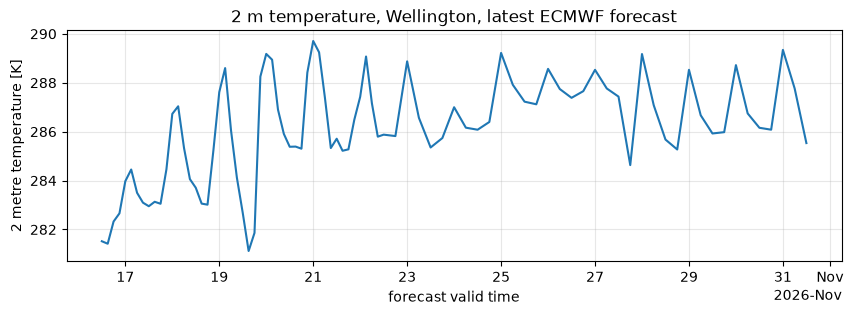

In [21]:
ecmwf_all.t2m.sel(longitude=174.8, latitude=-41.3, method="nearest").plot(figsize=(10, 3))
plt.title("2 m temperature, Wellington, latest ECMWF forecast"); plt.show()

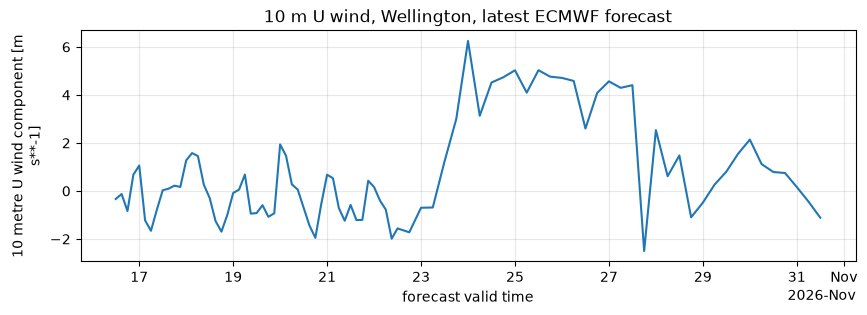

In [22]:
ecmwf_all.u10.sel(longitude=174.8, latitude=-41.3, method="nearest").plot(figsize=(10, 3))
plt.title("10 m U wind, Wellington, latest ECMWF forecast"); plt.show()